# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [3]:
derived_cols = ["ai_score", "ai_flag"]        # TODO: list the column(s) that ColdSense derived (not measured by the freezer or written by technicians)
n_alerts = int((df["ai_flag"] == 1).sum())            # TODO: number of rows with an alert (ai_flag == 1)
fault_rate_pct = round(100 * df["confirmed_fault"].mean(), 2)      # TODO: % of rows that are confirmed faults, 2 decimals (this is the base rate)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%%)


,fault hours
fault_type,
compressor trip,10
defrost heater stuck,11
sensor frozen,25


✏️ Your answer (Part 1): ai_score is quantitative and ai_flag is binary. Which visual channel suits each, and what information does the flag throw away that the score keeps?

Your answer: `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*
- **`ai_score` (Quantitative)**: Position along a common scale (e.g. y-axis on a scatter plot or line chart) or color saturation/luminance (using a continuous color scale) are excellent visual channels.
- **`ai_flag` (Binary)**: A categorical/identity visual channel like shape (e.g., cross vs circle) or hue/color categorizations (e.g., red vs grey) fits best.
- **Information lost by the flag**: The binary `ai_flag` throws away the continuous margin or confidence level of the prediction (e.g. a borderline score of 0.51 is treated identically to an extremely high score of 0.99, losing the strength and nuances of the alarm).

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

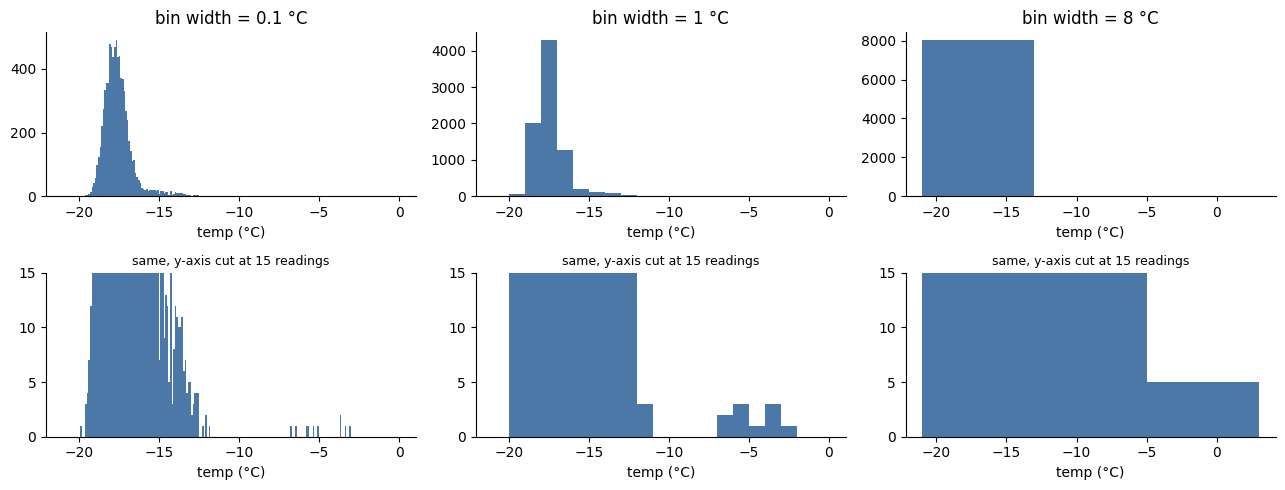

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]   # TODO: in the bottom row, which bin width(s) show the very warm readings (above -8 °C) as a separate group? a list, e.g. [0.1]
n_warm_readings = int((df["temp_c"] > -8).sum())          # TODO: how many readings are warmer than -8 °C? (count them with code)

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

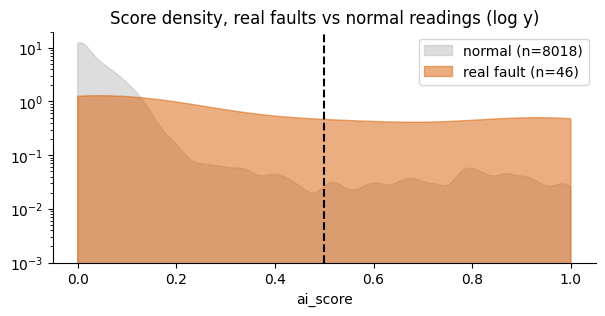

In [5]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # TODO: True/False - is there a clean score cut-off that separates real faults from normal readings?

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*
- A histogram is a **parameterised algorithm** because its appearance, shape, and information density depend entirely on two user-chosen parameters: the **bin width** (interval size) and the **bin alignment** (starting offset). Changing these parameters alters which features are visible or hidden.
- To the colleague, I would explain that **coarse bin choices wash out rare, small-scale variations**. In the 8 °C histogram, the extreme warm anomalies (which are very few in count) are lumped into the same large bin as the typical cold readings, completely masking the tail group. We must check smaller bin widths or zoom into the y-axis (limiting the upper bound) to uncover these hidden anomalies.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [6]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = float(np.max(np.abs((v - v.mean()) / np.std(v, ddof=1))))   # largest |z| using the sample SD
q1, q3 = np.percentile(v, [25, 75])
upper_fence = float(q3 + 1.5 * (q3 - q1))                           # Q3 + 1.5 * IQR

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*
The extreme value of $-3.6$ °C heavily inflates both the mean and standard deviation of the short window, causing a **masking** effect that keeps its own computed z-score below the threshold of 3. On the other hand, the IQR rule is highly robust because quartiles ignore extreme values, leaving the calculated threshold unaffected by the single massive spike.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [7]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())    # TODO: alerts that were real faults
FP = int((flag & ~real).sum())   # TODO: alerts on normal readings (false alarms)
FN = int((~flag & real).sum())   # TODO: real faults with no alert (missed)
TN = int((~flag & ~real).sum())  # TODO: normal readings with no alert

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [8]:
precision = TP / (TP + FP)              # TODO
recall = TP / (TP + FN)                 # TODO
f1 = 2 * (precision * recall) / (precision + recall)                     # TODO
accuracy = (TP + TN) / (TP + FP + FN + TN)               # TODO
flag_nothing_accuracy = TN / (TP + FP + FN + TN)  # TODO: accuracy of a "detector" that never raises an alert

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 97.7%



✏️ Your answer (Part 4): Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

Your answer:

* **Honest Rewording**: "ColdSense has a **precision of 10.1%** and a **recall of 34.8%**. While its overall accuracy is 97.9%, this is almost entirely because freezer faults are extremely rare (a 'never-alert' predictor achieves 97.7% accuracy)."
* **What this means for Ravi's team in plain words**:
  - **9 out of every 10 alerts are false alarms** (143 out of 159 total alarms raised are wasted night call-outs).
  - **Nearly two-thirds of all actual faults are completely missed** (30 out of 46 actual faults went undetected without any alert).


---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

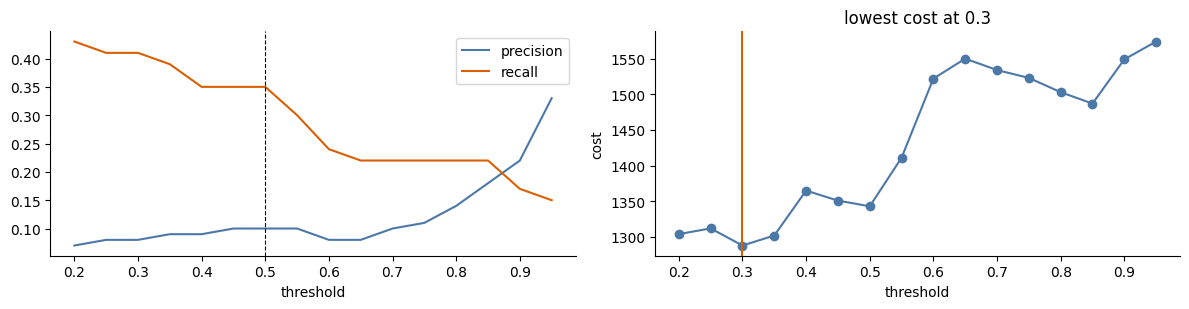

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [9]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]
best_threshold = sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

✏️ Your answer (Part 5): Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at which faults are never scored high.)

Your answer:
- The cost is lowest at a threshold of about **0.30**, but only slightly lower than at 0.50 (1288 vs 1343), and recall is still only about 41%. Moving the threshold just trades missed faults for false alarms.
- The reason is that the misses are **structural**, not a matter of cut-off. The 25 **"sensor frozen"** hours score close to zero (all below 0.1): the frozen sensor reports a perfectly normal -18.0 °C, so a detector that looks at one reading at a time sees nothing wrong. Those faults make up more than half of all 46 real faults, so recall is capped at roughly 46% (21 of 46) no matter how low the threshold goes.
- Lowering the threshold still adds false alarms (264 at 0.20, compared with 143 at 0.50), and the real faults it gains are mostly the ones the detector already half-sees (compressor trips, defrost-heater faults). Fixing the sensor-frozen blind spot needs a different kind of detector (a run-based check), not a different threshold.


---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

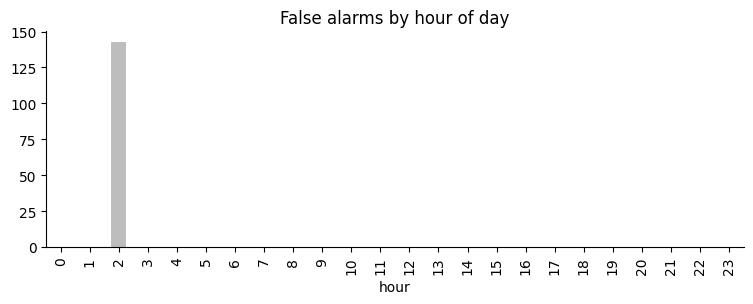

100% of false alarms happen at 2:00
For comparison, real faults by hour: {7: 1, 8: 1, 9: 2, 10: 3, 11: 3, 12: 3, 13: 4, 14: 4, 15: 6, 16: 6, 17: 4, 18: 3, 19: 2, 20: 2, 21: 1, 22: 1}


In [10]:
fp_rows = df[flag & ~real]
fp_by_hour = fp_rows.groupby("hour").size().reindex(range(24), fill_value=0)
fp_by_hour.plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_by_hour.idxmax())                      # hour with the most false alarms
fp_share_at_peak = float(fp_by_hour.max() / fp_by_hour.sum())   # share of all false alarms in that hour

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")
    print(f"For comparison, real faults by hour: {df[real].groupby('hour').size().to_dict()}")

### 6b · Which faults does ColdSense miss?

In [11]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = caught.index[caught.caught == 0][0]   # the fault type ColdSense never catches
anomaly_kind = "collective"   # a frozen sensor: every single reading (-18.0) looks perfectly normal, only the long flat run is abnormal

print(f"never caught: {never_caught_type} -> {anomaly_kind} anomaly")

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


never caught: sensor frozen -> collective anomaly


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [12]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

# context-aware z: compare with the same freezer at the same hour (guard against MAD = 0)
df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"].replace(0, np.nan)

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


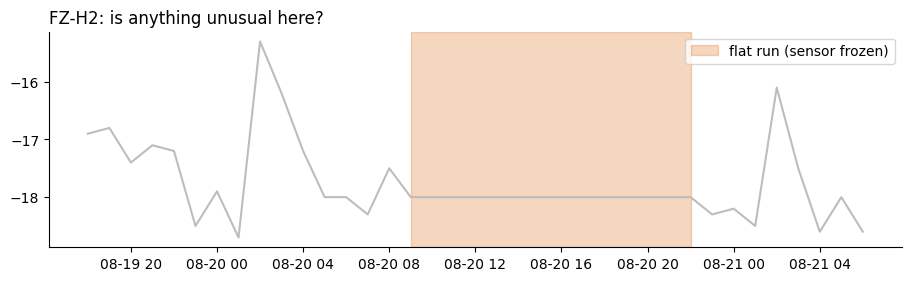

In [13]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]   # 6 hours in a row with (almost) no variation

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # highlight the WHOLE flat span (the rolling window ends on the flagged row, so the run starts 5 h earlier)
    fh2 = flat[flat.freezer_id == "FZ-H2"]
    ax.axvspan(fh2.timestamp.min() - pd.Timedelta(hours=5), fh2.timestamp.max(), color=ACCENT, alpha=.25, label="flat run (sensor frozen)")
    ax.legend(loc="upper right")
    ax.set_title("FZ-H2: is anything unusual here?", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

**(a)** Corrected statement: *"All 143 of ColdSense's false alarms happen at 02:00, during the normal defrost cycle. Real faults happen in the daytime (07:00–22:00, busiest around 15:00–16:00) and none were confirmed at 2 am."* The 2 am peak in the alerts is a pattern in the **false alarms**, not in the faults: the defrost heater warms the coil, the temperature rises as designed, and ColdSense scores it as abnormal. A night technician hired on that basis would be called out every night for nothing (143 wasted call-outs in six weeks, 100% of the 2 am alerts), while the real faults happen during the day and the missed ones (frozen sensors) would still go unnoticed.

**(b)** Not true. All 109 normal readings at or above -14 °C happen at 02:00, which is a **contextual anomaly** case: the same value is normal in one context (the 02:00–04:00 defrost window) and abnormal in another (e.g. 14:00 on a busy afternoon; the confirmed defrost-heater faults show up as -14 to -15 °C readings between 13:00 and 18:00). For a viewer to judge such an alert, the chart must show the **context** next to the reading: the expected band for that freezer at that hour of day (e.g. the hour-of-day median ± spread), the defrost window shaded, and ideally door openings. In the context-aware baseline (6c) the 2 am readings are no longer flagged.

**(c)** FZ-H2 did have a fault: a **"sensor frozen"** episode on 20 Aug (09:00–22:00, 14 hours of exactly -18.0 °C), logged and confirmed by technicians. FZ-P1 had a similar 11-hour episode on 6 Sep. The statement is wrong because the sensor kept reporting a perfectly normal value, so nothing looked like a fault. This is a **collective anomaly**: no single reading is abnormal (-18.0 °C is exactly what we expect), only the run is, because a real freezer's temperature always varies a little from hour to hour. A detector that scores readings one at a time never looks at the run, so it can never see it (0 of 25 such hours were caught). It needs a window-based feature, such as the rolling standard deviation of the last 6 hours.


---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

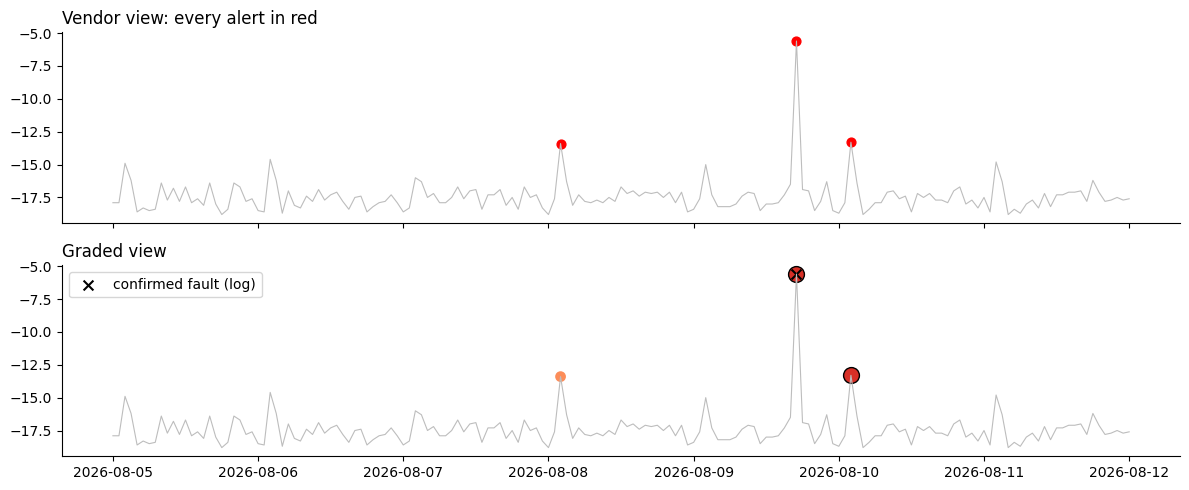

In [14]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90:   # strong: big, saturated, dark outline
        return ("#d73027", 130, "black")
    if score >= 0.70:   # moderate: medium, softer colour
        return ("#fc8d59", 60, "none")
    if score >= 0.50:   # subtle: small hollow-looking marker with an outline only
        return ("white", 30, "#fc8d59")
    return ("none", 0, "none")   # below 0.5: no emphasis, the line itself stays visible

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

score >= 0.9: 37 alerts, 22% real | score 0.5-0.7: 55 alerts, 11% real


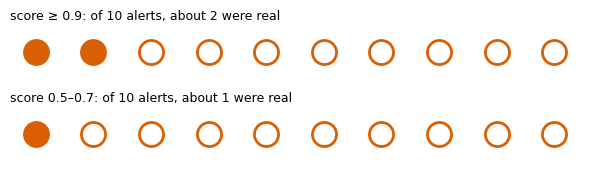

In [15]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(10 * band_hi.confirmed_fault.mean()))   # real faults per 10 alerts, score >= 0.9
real_per_10_lo = int(round(10 * band_lo.confirmed_fault.mean()))   # same for scores 0.5-0.7
print(f"score >= 0.9: {len(band_hi)} alerts, {band_hi.confirmed_fault.mean():.0%} real | score 0.5-0.7: {len(band_lo)} alerts, {band_lo.confirmed_fault.mean():.0%} real")

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*

**(a)** Salience is limited: when every alert is the same bright red, the red dots compete for attention and, since about 9 in 10 of them are false alarms, the team learns to ignore them or to chase them blindly. Attention gets used up on the loud, mostly false 2 am dots, and the frozen sensor (a flat, silent line with no dot at all) is the thing that is *not* highlighted. **Inattentional blindness** does the rest: people who are focused on checking the red dots do not notice an unexpected thing that has no salient cue, even when it is in plain view (a perfectly flat line). Scaling emphasis to confidence (7a) reduces the noise, and the flat span still needs its own visual cue (6d).

**(b)** Frequency framing: *"Of 10 alerts with a score of 0.9 or above, about 2 turned out to be real faults (37 such alerts, 8 real). Of 10 alerts with a score of 0.5–0.7, about 1 was real (55 alerts, 6 real)."* A score of 0.92 is a ranking signal, not a 92% probability. Even the highest band is wrong about 4 times in 5, although the higher bands are still worth checking before the low ones.


---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [16]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)              # standard error of the baseline mean
z_sd = (new_reading - mu) / sd    # how unusual is ONE new reading?
z_se = (new_reading - mu) / se    # (misused) distance in units of the uncertainty of the mean

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = "SD"   # a single new reading is judged against the spread of readings, not the spread of the mean

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*
- **SD (standard deviation):** describes how much individual readings vary around the baseline mean (here about 0.61 °C at 14:00 for FZ-B1), so it is the right yardstick for judging a single new reading.
- **SE (standard error):** describes how precisely we know the baseline *mean* (SD / √n, here about 0.09 °C with n = 42), so it gets smaller as more history is collected and says nothing about how much a single reading can vary.
- **Rewrite of statement 8:** *"A new FZ-B1 reading of -15.9 °C at 14:00 is about 2.3 standard deviations above the usual 14:00 level (-17.3 °C). That is unusual and worth a look, but a reading this far out is expected from normal variation roughly 1 time in 50 and is not a definite fault. The vendor's '15 standard errors' divides by the wrong quantity (the uncertainty of the average rather than the spread of the readings)."*


---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [17]:
decisions = {
    1: "Correct",   # 97.9% accurate, so trustworthy
    2: "Reject",    # most faults happen around 2 am
    3: "Accept",    # all 10 compressor trips caught
    4: "Reject",    # FZ-H2 had no fault
    5: "Reject",    # -14 °C is abnormal at any time
    6: "Reject",    # score 0.92 = 92% chance
    7: "Correct",   # threshold 0.5 is best
    8: "Reject",    # 15 standard errors: definite fault
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject     5
Correct    2
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*

Triage result: 1 of 8 vendor statements is accepted as written (#3), 2 need correcting (#1, #7) and 5 are rejected (#2, #4, #5, #6, #8).

**Anomaly review view (one screen per freezer, with a fleet overview on top):**
1. **Main view:** time series of temperature for the selected freezer with the alert score as a graded marker (strong ≥ 0.9, moderate 0.7–0.9, subtle outline 0.5–0.7, nothing below 0.5) rather than one red dot for everything. The confirmed-fault log is shown with its own marker.
2. **Context:** the expected band for that freezer at that hour of day (median ± spread), the 02:00–04:00 defrost window shaded, plus door openings and compressor kW as small aligned panels. This makes defrost spikes look normal and a day-time -14 °C obviously wrong. A visible flat-run highlight (rolling SD ≈ 0) covers the frozen-sensor case that the score never flags.
3. **Queue:** a ranked list of alerts with columns for score, hour, how far the reading is outside its hour-of-day band, the same freezer's recent history and a status (new / checked / confirmed / false alarm). The queue has a separate "check this sensor" lane for flat-run candidates. Alerts inside the defrost window are down-ranked or grouped instead of shown as separate call-outs.
4. **Verification tools:** one click to see the reading against the same hour on previous days, compare with other freezers in the same city at the same time, see neighbouring readings, and record "false alarm / real / sensor issue" with a note; a "call a technician" action is offered only after at least one of these checks.
5. **Evaluation:** a small panel that updates from the technicians' own labels: precision and recall of the current threshold (not accuracy), wasted call-outs per week, missed faults, and an expected-cost curve for a missed fault (≈ 40) vs a false call-out (≈ 1), so the threshold can be adjusted on evidence. Scores are shown in frequency form ("about 2 in 10 alerts at this level were real").


---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:* Statement 1 ("97.9% accurate") was the most convincing at first glance: a single large, precise-looking number with a confident conclusion attached. It only fell apart once I saw that a detector that never raises an alert scores 97.7%, so the number says almost nothing about the alerts. Without the maintenance log I could not have computed precision and recall at all, and I probably would not have found the frozen H2 sensor, because it produces no alert and no outlier.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:* The cold-chain lead (Ravi), together with whoever owns stock loss and technician time, should own it, not the vendor, because the trade-off is a business cost (a spoiled freezer ≈ 40 units vs a wasted call-out ≈ 1). The dashboard should show precision, recall and the expected-cost curve at each threshold, with the number of call-outs per week at the chosen setting. In this data the cost minimum is around 0.30 but it is only slightly better than 0.50, which is a reminder that the threshold cannot fix the missed faults.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:* Un-inspected alerts would count as "no fault", so precision would look worse than it is, and faults that nobody noticed (like the frozen sensor) would never be labelled at all, so recall would look better than it is. The review workflow can reduce this by recording a verdict for every alert that is checked, by sampling some low-score readings and flat runs for spot-checks, and by feeding those labels back into the evaluation panel.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:* Show each alert as a candidate with its evidence, instead of a verdict: the reading against its hour-of-day band, a frequency-framed confidence ("about 2 in 10 alerts at this level were real") and a required "checked / false alarm" step before a call-out is made. This turns the red dot into a prompt to look at the context, and the graded emphasis makes high-confidence alerts stand out without making low-confidence ones look like emergencies.
